# Industrial Machine Failure Classification Using Physics-Informed Feature Engineering

**Proyecto 01 — Industrial ML | Portfolio**  
**Dataset:** AI4I 2020, réplica CSV de Kaggle (`shivamb/machine-predictive-maintenance-classification`)  
**Propósito:** clasificación de registros con y sin falla mediante variables operativas.

> **Alcance:** conjunto sintético; clasificación contemporánea, **no** pronóstico de fallas futuras. Las cifras son exploratorias, no una validación externa independiente.

## 1. Carga y exploración


In [25]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

import pandas as pd
import os

# Ver los archivos disponibles
for carpeta, _, archivos in os.walk("/kaggle/input"):
    for archivo in archivos:
        print(os.path.join(carpeta, archivo))

/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv
/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv


In [26]:
df = pd.read_csv("/kaggle/input/datasets/shivamb/machine-predictive-maintenance-classification/predictive_maintenance.csv")

display(df.head())
print(df.shape)

,UDI,Product ID,Type,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target,Failure Type
0,1,M14860,M,298.1,308.6,1551,42.8,0,0,No Failure
1,2,L47181,L,298.2,308.7,1408,46.3,3,0,No Failure
2,3,L47182,L,298.1,308.5,1498,49.4,5,0,No Failure
3,4,L47183,L,298.2,308.6,1433,39.5,7,0,No Failure
4,5,L47184,L,298.2,308.7,1408,40.0,9,0,No Failure


(10000, 10)


In [27]:

# Estadísticas descriptivas
display(df.describe())

# Valores faltantes
print("Valores faltantes:")
print(df.isnull().sum())

# Distribución de fallas
print("Distribución de fallas:")
print(df["Failure Type"].value_counts())

# Porcentaje de fallas
print(df["Failure Type"].value_counts(normalize=True) * 100)


,UDI,Air temperature [K],Process temperature [K],Rotational speed [rpm],Torque [Nm],Tool wear [min],Target
count,10000.00000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000
mean,5000.50000,300.004930,310.005560,1538.776100,39.986910,107.951000,0.033900
std,2886.89568,2.000259,1.483734,179.284096,9.968934,63.654147,0.180981
min,1.00000,295.300000,305.700000,1168.000000,3.800000,0.000000,0.000000
25%,2500.75000,298.300000,308.800000,1423.000000,33.200000,53.000000,0.000000
50%,5000.50000,300.100000,310.100000,1503.000000,40.100000,108.000000,0.000000
75%,7500.25000,301.500000,311.100000,1612.000000,46.800000,162.000000,0.000000
max,10000.00000,304.500000,313.800000,2886.000000,76.600000,253.000000,1.000000


Valores faltantes:
UDI                        0
Product ID                 0
Type                       0
Air temperature [K]        0
Process temperature [K]    0
Rotational speed [rpm]     0
Torque [Nm]                0
Tool wear [min]            0
Target                     0
Failure Type               0
dtype: int64
Distribución de fallas:
Failure Type
No Failure                  9652
Heat Dissipation Failure     112
Power Failure                 95
Overstrain Failure            78
Tool Wear Failure             45
Random Failures               18
Name: count, dtype: int64
Failure Type
No Failure                  96.52
Heat Dissipation Failure     1.12
Power Failure                0.95
Overstrain Failure           0.78
Tool Wear Failure            0.45
Random Failures              0.18
Name: proportion, dtype: float64


### Definición del objetivo
Se utiliza `y = (df["Failure Type"] != "No Failure").astype(int)` para mantener coherencia con los experimentos originales. **Importante:** la columna `Target` suministrada por este CSV tiene una prevalencia diferente; no son etiquetas intercambiables y debe analizarse esta diferencia antes de utilizar el trabajo como benchmark oficial. Se excluyen de los predictores ambas etiquetas, IDs y cualquier indicador derivado del tipo de falla.

## 2. División estratificada y modelo base


In [28]:

from sklearn.model_selection import train_test_split
import pandas as pd

# Variable objetivo binaria
y = (df["Failure Type"] != "No Failure").astype(int)

# Variables de entrada
variables = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X = df[variables].copy()

# Convertir Type en variables numéricas
X = pd.get_dummies(X, columns=["Type"], dtype=int)

# Separar entrenamiento y prueba
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Entrenamiento:", X_train.shape)
print("Prueba:", X_test.shape)

print("\nDistribución en entrenamiento:")
print(y_train.value_counts())

print("\nDistribución en prueba:")
print(y_test.value_counts())


Entrenamiento: (8000, 8)
Prueba: (2000, 8)

Distribución en entrenamiento:
Failure Type
0    7722
1     278
Name: count, dtype: int64

Distribución en prueba:
Failure Type
0    1930
1      70
Name: count, dtype: int64


RESULTADOS DEL MODELO
              precision    recall  f1-score   support

      Normal       0.99      0.94      0.96      1930
       Falla       0.32      0.83      0.47        70

    accuracy                           0.93      2000
   macro avg       0.66      0.88      0.72      2000
weighted avg       0.97      0.93      0.95      2000



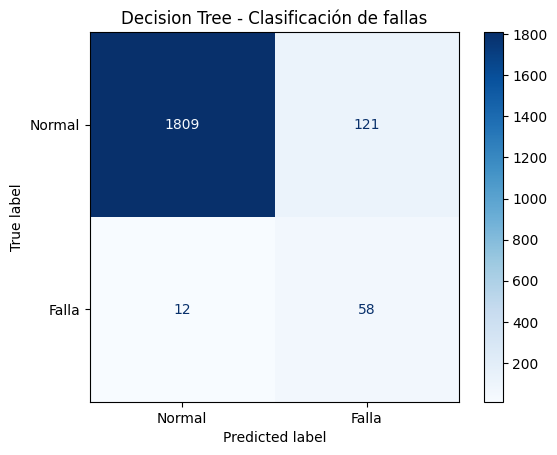

In [29]:

from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt

# Crear el modelo
modelo = DecisionTreeClassifier(
    max_depth=5,
    class_weight="balanced",
    random_state=42
)

# Entrenar con los 8000 registros
modelo.fit(X_train, y_train)

# Predecir los 2000 registros de prueba
y_pred = modelo.predict(X_test)

# Evaluar los resultados
print("RESULTADOS DEL MODELO")
print(classification_report(
    y_test,
    y_pred,
    target_names=["Normal", "Falla"],
    zero_division=0
))

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    display_labels=["Normal", "Falla"],
    cmap="Blues"
)

plt.title("Decision Tree - Clasificación de fallas")
plt.show()


RESULTADOS RANDOM FOREST
              precision    recall  f1-score   support

      Normal       0.99      0.99      0.99      1930
       Falla       0.81      0.73      0.77        70

    accuracy                           0.98      2000
   macro avg       0.90      0.86      0.88      2000
weighted avg       0.98      0.98      0.98      2000

Average Precision: 0.8156


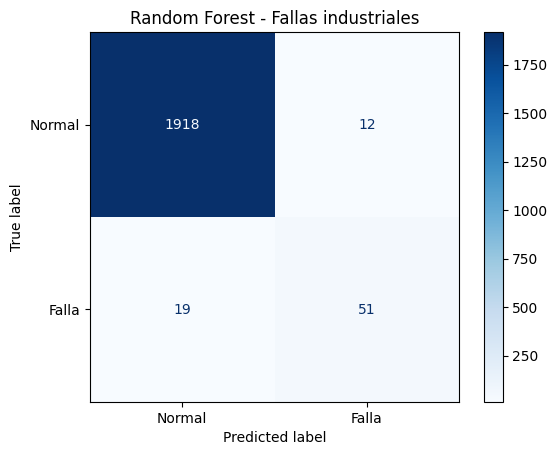

In [30]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    ConfusionMatrixDisplay,
    average_precision_score
)
import matplotlib.pyplot as plt

# Crear modelo Random Forest
modelo_rf = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Entrenar
modelo_rf.fit(X_train, y_train)

# Predecir
y_pred_rf = modelo_rf.predict(X_test)
y_prob_rf = modelo_rf.predict_proba(X_test)[:, 1]

# Resultados
print("RESULTADOS RANDOM FOREST")

print(classification_report(
    y_test,
    y_pred_rf,
    target_names=["Normal", "Falla"],
    zero_division=0
))

print(
    "Average Precision:",
    round(
        average_precision_score(y_test, y_prob_rf),
        4
    )
)

# Matriz de confusión
ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred_rf,
    display_labels=["Normal", "Falla"],
    cmap="Blues"
)

plt.title("Random Forest - Fallas industriales")
plt.show()


## 3. Importancia de características y elaboración de variables físicas
Las importancias de impureza en árboles **no son causalidad**. Potencia mecánica y diferencial térmico se construyen exclusivamente a partir de medidas de entrada.


Torque [Nm]                0.296235
Rotational speed [rpm]     0.295584
Tool wear [min]            0.201260
Air temperature [K]        0.110524
Process temperature [K]    0.077349
Type_L                     0.008623
Type_M                     0.006148
Type_H                     0.004277
dtype: float64


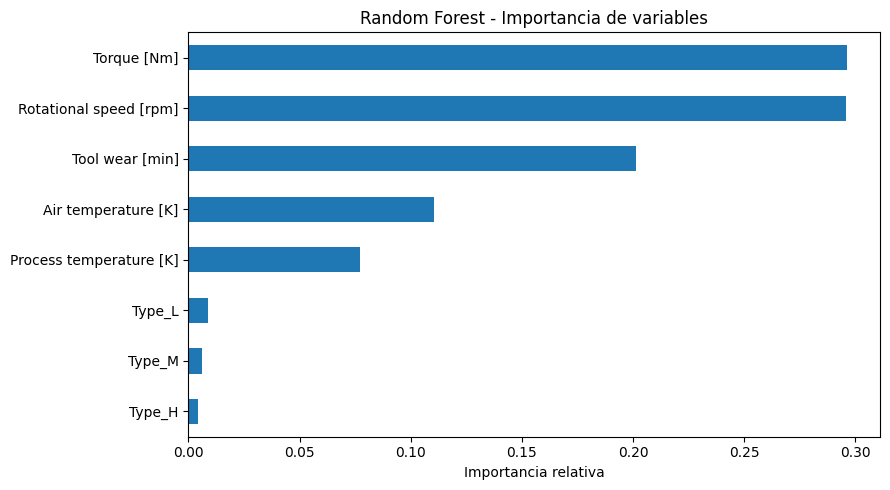

In [31]:

import pandas as pd
import matplotlib.pyplot as plt

# Importancia de las variables en Random Forest
importancias = pd.Series(
    modelo_rf.feature_importances_,
    index=X_train.columns
).sort_values(ascending=False)

print(importancias)

plt.figure(figsize=(9, 5))
importancias.sort_values().plot(kind="barh")

plt.xlabel("Importancia relativa")
plt.title("Random Forest - Importancia de variables")
plt.tight_layout()
plt.show()


In [32]:

import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    average_precision_score
)

# Partimos de los conjuntos originales
X_train_fe = X_train.copy()
X_test_fe = X_test.copy()

for datos in [X_train_fe, X_test_fe]:

    # Potencia mecánica aproximada en kW
    datos["Power_kW"] = (
        datos["Torque [Nm]"]
        * 2 * np.pi
        * datos["Rotational speed [rpm]"]
        / 60 / 1000
    )

    # Diferencia de temperaturas en K
    datos["Delta_T"] = (
        datos["Process temperature [K]"]
        - datos["Air temperature [K]"]
    )

# Nuevo modelo con las mismas condiciones
modelo_rf_fe = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

modelo_rf_fe.fit(X_train_fe, y_train)

pred_fe = modelo_rf_fe.predict(X_test_fe)
prob_fe = modelo_rf_fe.predict_proba(X_test_fe)[:, 1]

print("RANDOM FOREST CON FEATURE ENGINEERING")

print(classification_report(
    y_test,
    pred_fe,
    target_names=["Normal", "Falla"],
    zero_division=0
))

print(
    "Average Precision:",
    round(average_precision_score(y_test, prob_fe), 4)
)


RANDOM FOREST CON FEATURE ENGINEERING
              precision    recall  f1-score   support

      Normal       0.99      1.00      1.00      1930
       Falla       0.92      0.80      0.85        70

    accuracy                           0.99      2000
   macro avg       0.96      0.90      0.93      2000
weighted avg       0.99      0.99      0.99      2000

Average Precision: 0.8974


## 4. Validación cruzada y estudio de ablación
La CV estratificada se efectúa sobre el conjunto de entrenamiento, comparando modelos y conjuntos de características. El dataset es sintético y no proporciona una secuencia temporal verificable para predicción a futuro.


In [33]:

from sklearn.model_selection import StratifiedKFold, cross_validate
from sklearn.ensemble import RandomForestClassifier
import pandas as pd

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

def validar_modelo(X_datos, y_datos):

    modelo = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    resultados = cross_validate(
        modelo,
        X_datos,
        y_datos,
        cv=cv,
        scoring={
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "ap": "average_precision"
        },
        n_jobs=-1
    )

    return {
        metrica: (
            resultados["test_" + metrica].mean(),
            resultados["test_" + metrica].std()
        )
        for metrica in ["precision", "recall", "f1", "ap"]
    }

# Comparar únicamente con datos de entrenamiento
original = validar_modelo(X_train, y_train)
con_fisica = validar_modelo(X_train_fe, y_train)

tabla = pd.DataFrame({
    "RF original": {
        k: f"{v[0]:.3f} ± {v[1]:.3f}"
        for k, v in original.items()
    },
    "RF + Física": {
        k: f"{v[0]:.3f} ± {v[1]:.3f}"
        for k, v in con_fisica.items()
    }
})

display(tabla)


,RF original,RF + Física
precision,0.722 ± 0.028,0.895 ± 0.041
recall,0.594 ± 0.084,0.731 ± 0.064
f1,0.650 ± 0.058,0.803 ± 0.047
ap,0.702 ± 0.041,0.833 ± 0.057


In [34]:

import pandas as pd
import numpy as np
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate, StratifiedKFold

# Datos de entrenamiento: no utilizar el conjunto de prueba
base = X_train.copy()

potencia = base.copy()
potencia["Power_kW"] = (
    potencia["Torque [Nm]"]
    * 2 * np.pi
    * potencia["Rotational speed [rpm]"]
    / 60 / 1000
)

temperatura = base.copy()
temperatura["Delta_T"] = (
    temperatura["Process temperature [K]"]
    - temperatura["Air temperature [K]"]
)

ambas = potencia.copy()
ambas["Delta_T"] = temperatura["Delta_T"]

experimentos = {
    "Original": base,
    "Solo potencia": potencia,
    "Solo Delta_T": temperatura,
    "Ambas": ambas
}

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados = []

for nombre, datos in experimentos.items():

    modelo = RandomForestClassifier(
        n_estimators=200,
        min_samples_leaf=3,
        class_weight="balanced",
        random_state=42,
        n_jobs=-1
    )

    scores = cross_validate(
        modelo,
        datos,
        y_train,
        cv=cv,
        scoring={
            "precision": "precision",
            "recall": "recall",
            "f1": "f1",
            "ap": "average_precision"
        },
        n_jobs=-1
    )

    resultados.append({
        "Modelo": nombre,
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "AP": scores["test_ap"].mean()
    })

tabla = pd.DataFrame(resultados)
display(tabla.round(4))


,Modelo,Precision,Recall,F1,AP
0,Original,0.7221,0.5940,0.6496,0.7023
1,Solo potencia,0.8449,0.6801,0.7523,0.8002
2,Solo Delta_T,0.8355,0.6622,0.7384,0.7809
3,Ambas,0.8949,0.7305,0.8031,0.8325


## 5. Selección exploratoria del umbral (Random Forest)
El umbral 0,45 fue elegido utilizando predicciones *out-of-fold*; el F1 resultante es una métrica de **selección**, no una medida independiente del procedimiento completo.


In [35]:

import numpy as np
import pandas as pd

from sklearn.model_selection import (
    StratifiedKFold,
    cross_val_predict
)
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score
)

# Modelo seleccionado
modelo = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Probabilidades out-of-fold
prob_cv = cross_val_predict(
    modelo,
    X_train_fe,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)[:, 1]

# Evaluar distintos umbrales
umbrales = np.arange(0.10, 0.91, 0.05)

resultados = []

for umbral in umbrales:

    pred = (prob_cv >= umbral).astype(int)

    resultados.append({
        "Umbral": round(umbral, 2),
        "Precision": precision_score(
            y_train, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_train, pred, zero_division=0
        ),
        "F1": f1_score(
            y_train, pred, zero_division=0
        ),
        "Falsas alarmas": int(
            ((pred == 1) & (y_train == 0)).sum()
        ),
        "Fallas omitidas": int(
            ((pred == 0) & (y_train == 1)).sum()
        )
    })

tabla_umbrales = pd.DataFrame(resultados)

display(tabla_umbrales.round(3))


,Umbral,Precision,Recall,F1,Falsas alarmas,Fallas omitidas
0,0.10,0.297,0.899,0.447,591,28
1,0.15,0.393,0.871,0.542,373,36
2,0.20,0.487,0.849,0.619,249,42
3,0.25,0.592,0.831,0.692,159,47
4,0.30,0.704,0.813,0.755,95,52
5,0.35,0.771,0.799,0.784,66,56
6,0.40,0.828,0.777,0.801,45,62
7,0.45,0.872,0.759,0.812,31,67
8,0.50,0.894,0.730,0.804,24,75
9,0.55,0.915,0.694,0.789,18,85


In [36]:

# Guardar el umbral elegido
umbral_rf = 0.45

# Evaluación out-of-fold con ese umbral
pred_cv = (prob_cv >= umbral_rf).astype(int)

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

print("RANDOM FOREST + FEATURES FÍSICAS")
print("Umbral:", umbral_rf)

print(classification_report(
    y_train,
    pred_cv,
    target_names=["Normal", "Falla"],
    zero_division=0
))

print("Matriz de confusión:")
print(confusion_matrix(y_train, pred_cv))


RANDOM FOREST + FEATURES FÍSICAS
Umbral: 0.45
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      7722
       Falla       0.87      0.76      0.81       278

    accuracy                           0.99      8000
   macro avg       0.93      0.88      0.90      8000
weighted avg       0.99      0.99      0.99      8000

Matriz de confusión:
[[7691   31]
 [  67  211]]


## 6. Comparación exploratoria con XGBoost
Los nombres de columnas se normalizan porque esta versión de XGBoost rechaza los corchetes de unidades. XGBoost y Random Forest requieren comparación bajo criterios equivalentes.


In [37]:

# Crear una copia para XGBoost
X_train_xgb = X_train_fe.copy()

# Limpiar nombres de columnas
X_train_xgb.columns = (
    X_train_xgb.columns
    .str.replace("[", "", regex=False)
    .str.replace("]", "", regex=False)
    .str.replace("<", "", regex=False)
    .str.replace(" ", "_", regex=False)
)

print(X_train_xgb.columns.tolist())


['Air_temperature_K', 'Process_temperature_K', 'Rotational_speed_rpm', 'Torque_Nm', 'Tool_wear_min', 'Type_H', 'Type_L', 'Type_M', 'Power_kW', 'Delta_T']


In [38]:

from xgboost import XGBClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

negativos = (y_train == 0).sum()
positivos = (y_train == 1).sum()

modelo_xgb = XGBClassifier(
    n_estimators=200,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    scale_pos_weight=negativos / positivos,
    objective="binary:logistic",
    eval_metric="logloss",
    random_state=42,
    n_jobs=2
)

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

resultados_xgb = cross_validate(
    modelo_xgb,
    X_train_xgb,
    y_train,
    cv=cv,
    scoring={
        "precision": "precision",
        "recall": "recall",
        "f1": "f1",
        "ap": "average_precision"
    },
    n_jobs=1,
    error_score="raise"
)

print("RESULTADOS XGBOOST")

for metrica in ["precision", "recall", "f1", "ap"]:
    valores = resultados_xgb["test_" + metrica]
    print(
        f"{metrica}: "
        f"{valores.mean():.4f} ± {valores.std():.4f}"
    )


RESULTADOS XGBOOST
precision: 0.5456 ± 0.0250
recall: 0.8312 ± 0.0359
f1: 0.6584 ± 0.0257
ap: 0.8150 ± 0.0325


In [39]:

from sklearn.model_selection import cross_val_predict
from sklearn.metrics import (
    precision_score,
    recall_score,
    f1_score,
    average_precision_score
)
import numpy as np
import pandas as pd

# Predicciones de validación cruzada
prob_xgb = cross_val_predict(
    modelo_xgb,
    X_train_xgb,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=1
)[:, 1]

# Analizar diferentes umbrales
resultados = []

for umbral in np.arange(0.10, 0.91, 0.01):

    pred = (prob_xgb >= umbral).astype(int)

    resultados.append({
        "Umbral": round(umbral, 2),
        "Precision": precision_score(
            y_train, pred, zero_division=0
        ),
        "Recall": recall_score(
            y_train, pred, zero_division=0
        ),
        "F1": f1_score(
            y_train, pred, zero_division=0
        ),
        "Falsas alarmas": int(
            ((pred == 1) & (y_train == 0)).sum()
        ),
        "Fallas omitidas": int(
            ((pred == 0) & (y_train == 1)).sum()
        )
    })

tabla_xgb = pd.DataFrame(resultados)

# Mostrar los 10 mejores umbrales por F1
display(
    tabla_xgb.sort_values(
        "F1", ascending=False
    ).head(10).round(4)
)

print(
    "Average Precision XGBoost:",
    round(average_precision_score(y_train, prob_xgb), 4)
)


,Umbral,Precision,Recall,F1,Falsas alarmas,Fallas omitidas
63,0.73,0.7920,0.7806,0.7862,57,61
65,0.75,0.8068,0.7662,0.7860,51,65
64,0.74,0.7963,0.7734,0.7847,55,63
69,0.79,0.8247,0.7446,0.7826,44,71
70,0.80,0.8247,0.7446,0.7826,44,71
68,0.78,0.8214,0.7446,0.7811,45,71
74,0.84,0.8481,0.7230,0.7806,36,77
62,0.72,0.7806,0.7806,0.7806,61,61
72,0.82,0.8327,0.7338,0.7801,41,74
73,0.83,0.8417,0.7266,0.7799,38,76


Average Precision XGBoost: 0.8111


## 7. Evaluación de demostración sobre otra partición
**Advertencia metodológica:** cambiar la semilla de división no genera una prueba realmente nueva: todos estos registros ya participaron en el desarrollo original. El informe debe identificarla como evaluación de demostración, no como rendimiento fuera de muestra independiente.


In [40]:

from sklearn.model_selection import train_test_split

# Reconstruimos el dataset a partir de las variables originales.
# No utilizamos columnas que indiquen el tipo de falla.

columnas = [
    "Type",
    "Air temperature [K]",
    "Process temperature [K]",
    "Rotational speed [rpm]",
    "Torque [Nm]",
    "Tool wear [min]"
]

X_total = pd.get_dummies(
    df[columnas].copy(),
    columns=["Type"],
    dtype=int
)

y_total = (
    df["Failure Type"] != "No Failure"
).astype(int)

X_dev, X_final, y_dev, y_final = train_test_split(
    X_total,
    y_total,
    test_size=0.20,
    stratify=y_total,
    random_state=123
)

print("Desarrollo:", X_dev.shape)
print("Evaluación:", X_final.shape)
print("Distribución desarrollo:")
print(y_dev.value_counts())
print("Distribución evaluación:")
print(y_final.value_counts())


Desarrollo: (8000, 8)
Evaluación: (2000, 8)
Distribución desarrollo:
Failure Type
0    7722
1     278
Name: count, dtype: int64
Distribución evaluación:
Failure Type
0    1930
1      70
Name: count, dtype: int64


In [41]:

import numpy as np

def agregar_variables_fisicas(X):
    datos = X.copy()

    # Potencia mecánica aproximada [kW]
    datos["Power_kW"] = (
        datos["Torque [Nm]"]
        * 2 * np.pi
        * datos["Rotational speed [rpm]"]
        / 60 / 1000
    )

    # Diferencia de temperatura [K]
    datos["Delta_T"] = (
        datos["Process temperature [K]"]
        - datos["Air temperature [K]"]
    )

    return datos

X_dev_fe = agregar_variables_fisicas(X_dev)
X_final_fe = agregar_variables_fisicas(X_final)

print("Variables de entrada:")
print(X_dev_fe.columns.tolist())
print("\nDimensiones:", X_dev_fe.shape)


Variables de entrada:
['Air temperature [K]', 'Process temperature [K]', 'Rotational speed [rpm]', 'Torque [Nm]', 'Tool wear [min]', 'Type_H', 'Type_L', 'Type_M', 'Power_kW', 'Delta_T']

Dimensiones: (8000, 10)


EVALUACIÓN DEL MODELO
              precision    recall  f1-score   support

      Normal       0.99      1.00      0.99      1930
       Falla       0.86      0.79      0.82        70

    accuracy                           0.99      2000
   macro avg       0.93      0.89      0.91      2000
weighted avg       0.99      0.99      0.99      2000

Average Precision: 0.8293
Matriz de confusión:
[[1921    9]
 [  15   55]]


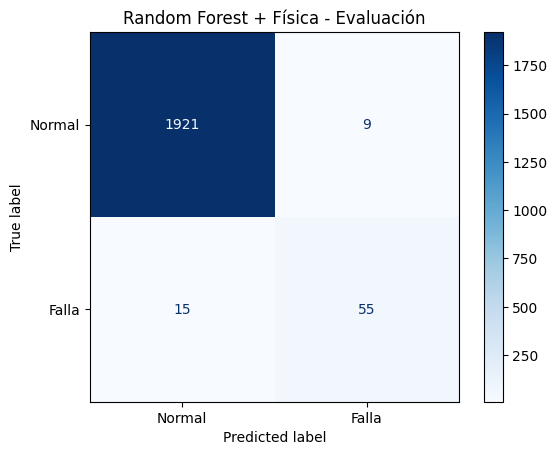

In [42]:

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    average_precision_score
)
import matplotlib.pyplot as plt

modelo_final = RandomForestClassifier(
    n_estimators=200,
    min_samples_leaf=3,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

# Entrenamiento con 8.000 registros
modelo_final.fit(X_dev_fe, y_dev)

# Probabilidades en los 2.000 registros de evaluación
prob_final = modelo_final.predict_proba(
    X_final_fe
)[:, 1]

# Aplicar umbral candidato
umbral_final = 0.45
pred_final = (prob_final >= umbral_final).astype(int)

print("EVALUACIÓN DEL MODELO")

print(classification_report(
    y_final,
    pred_final,
    target_names=["Normal", "Falla"],
    zero_division=0
))

print(
    "Average Precision:",
    round(
        average_precision_score(y_final, prob_final),
        4
    )
)

print("Matriz de confusión:")
print(confusion_matrix(y_final, pred_final))

ConfusionMatrixDisplay.from_predictions(
    y_final,
    pred_final,
    display_labels=["Normal", "Falla"],
    cmap="Blues"
)

plt.title("Random Forest + Física - Evaluación")
plt.show()


## 8. Conclusiones y mejoras pendientes

- En CV de cinco particiones, RF original obtuvo F1 ≈ 0,650; RF con potencia y ΔT obtuvo F1 ≈ 0,803.
- En las predicciones OOF de desarrollo, RF con umbral 0,45: 211 TP, 67 FN, 31 FP, 7.691 TN.
- La segunda división de demostración produjo 55 TP, 15 FN, 9 FP, 1.921 TN (AP 0,8293), **sin independencia metodológica**.
- El F1 para XGBoost a umbral optimizado 0,73 fue 0,7862 sobre OOF, no equivalente a una validación anidada.
- Para publicar una estimación robusta: validación anidada del **pipeline completo** (features, hiperparámetros y umbral), o recolección de un conjunto externo verdaderamente nuevo.
- Investigar las diferencias entre `Target` y la variable binaria derivada de `Failure Type` antes de reproducir comparaciones publicadas sobre AI4I.
- Para mantenimiento predictivo real: datos de equipos identificados, marcas de tiempo y horizonte de anticipación definido.
